# Practice Questions on course.csv

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [12]:
df=pd.read_table('course.csv')

# Data Loading and Cleaning

In [13]:
df

,"1,Mumbai,PQR institute .Pvt,BI,MH,9 Months"
0,"2,Delhi,ABC institute .Pvt.LTD,AI,UP,18 Months"
1,"3,Bengaluru,MNO institute .Ltd,Data Science,T..."
2,"4,Bhopal,RST institute .Pvt.LTD,ML,MP,3 Months"
3,"5,Mumbai,EFG institute .Pvt.LTD,DL,MH,3 Months"
4,"6,Hyderabad,LMN institute ,Could,AP,4 Months"
5,"7,Patna,DEF institute .Ltd,Web Serv,BH,4 Months"
6,"8,Channai,PQR institute .Pvt.LTD,AWS,KT,3 Months"
7,"9,Kolkata,UVW institute .Ltd,Networking,WB,3 ..."
8,"10,Hyderabad,GHI institute .Ltd,AI,AP,18 Months"
9,"11,Bhopal,IJK institute ,DL,MP,3 Months"


1. The CSV has no header. How do you load it with header=None and assign sensible names (ID, City, Institute, Course, State, Duration)? How many rows and columns does it have, and what are the data types?


In [14]:
colname=['Sr. No','City','Institute','Course','State','Duration']
df=pd.read_csv('course.csv',sep=',',header=None,names=colname)

In [15]:
df

,Sr. No,City,Institute,Course,State,Duration
0,1,Mumbai,PQR institute .Pvt,BI,MH,9 Months
1,2,Delhi,ABC institute .Pvt.LTD,AI,UP,18 Months
2,3,Bengaluru,MNO institute .Ltd,Data Science,TN,11 Months
3,4,Bhopal,RST institute .Pvt.LTD,ML,MP,3 Months
4,5,Mumbai,EFG institute .Pvt.LTD,DL,MH,3 Months
5,6,Hyderabad,LMN institute,Could,AP,4 Months
6,7,Patna,DEF institute .Ltd,Web Serv,BH,4 Months
7,8,Channai,PQR institute .Pvt.LTD,AWS,KT,3 Months
8,9,Kolkata,UVW institute .Ltd,Networking,WB,3 Months
9,10,Hyderabad,GHI institute .Ltd,AI,AP,18 Months


In [21]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 25 entries, 0 to 24
Data columns (total 6 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   Sr. No     25 non-null     int64
 1   City       25 non-null     str  
 2   Institute  25 non-null     str  
 3   Course     25 non-null     str  
 4   State      25 non-null     str  
 5   Duration   25 non-null     str  
dtypes: int64(1), str(5)
memory usage: 2.3 KB


* It has total 25 rows and 6 columns.
* 'Sr.No' column has int64 datatype and rest columns has str datatype. 

2. Are there missing values or duplicate rows? Is any institute name repeated?

In [30]:
df.isnull().sum()

Sr. No       0
City         0
Institute    0
Course       0
State        0
Duration     0
dtype: int64

In [32]:
df.duplicated().sum()

np.int64(0)

In [35]:
df.Institute.duplicated().sum()

np.int64(0)

3. Which spelling errors need fixing? Examples are “Channai” (Chennai), “Could” (Cloud), “Gj” (GJ) and “BH” (Bihar is usually BR). Could any other state codes be wrong?

In [42]:
df.City=df.City.replace({'Channai':'Chennai'})
df.Course=df.Course.replace({'Could':'Cloud'})
df.State=df.State.replace({'Gj':'GJ','BH':'BR','KT':'TN'})
df.loc[df.City=='Bengaluru','State']='KT'

In [43]:
df

,Sr. No,City,Institute,Course,State,Duration
0,1,Mumbai,PQR institute .Pvt,BI,MH,9 Months
1,2,Delhi,ABC institute .Pvt.LTD,AI,UP,18 Months
2,3,Bengaluru,MNO institute .Ltd,Data Science,KT,11 Months
3,4,Bhopal,RST institute .Pvt.LTD,ML,MP,3 Months
4,5,Mumbai,EFG institute .Pvt.LTD,DL,MH,3 Months
5,6,Hyderabad,LMN institute,Cloud,AP,4 Months
6,7,Patna,DEF institute .Ltd,Web Serv,BR,4 Months
7,8,Chennai,PQR institute .Pvt.LTD,AWS,TN,3 Months
8,9,Kolkata,UVW institute .Ltd,Networking,WB,3 Months
9,10,Hyderabad,GHI institute .Ltd,AI,AP,18 Months


4. Institute names have uneven spacing and inconsistent suffixes (.Pvt, .Pvt.LTD, .Ltd, or none). How do you strip the extra whitespace and extract a clean Institute_Type column (Pvt Ltd, Ltd, or Unspecified)?

In [54]:
df.Institute=df.Institute.str.strip()  # spaces at the start and end
df.Institute=df.Institute.str.replace("  ", " ")   # double space becomes single

In [55]:
def find_type(name):
    name=name.lower()
    if "pvt" in name:
        return "Pvt Ltd"
    elif "ltd" in name:
        return "Ltd"
    else:
        return "Unspecified"
    

In [56]:
df["Institute_type"] = df.Institute.apply(find_type)

In [57]:
df

,Sr. No,City,Institute,Course,State,Duration,Institute_type
0,1,Mumbai,PQR institute .Pvt,BI,MH,9 Months,Pvt Ltd
1,2,Delhi,ABC institute .Pvt.LTD,AI,UP,18 Months,Pvt Ltd
2,3,Bengaluru,MNO institute .Ltd,Data Science,KT,11 Months,Ltd
3,4,Bhopal,RST institute .Pvt.LTD,ML,MP,3 Months,Pvt Ltd
4,5,Mumbai,EFG institute .Pvt.LTD,DL,MH,3 Months,Pvt Ltd
5,6,Hyderabad,LMN institute,Cloud,AP,4 Months,Unspecified
6,7,Patna,DEF institute .Ltd,Web Serv,BR,4 Months,Ltd
7,8,Chennai,PQR institute .Pvt.LTD,AWS,TN,3 Months,Pvt Ltd
8,9,Kolkata,UVW institute .Ltd,Networking,WB,3 Months,Ltd
9,10,Hyderabad,GHI institute .Ltd,AI,AP,18 Months,Ltd


5. Duration is a string like “18 Months”. How do you convert it to an integer Duration_Months?


In [64]:
df['Duration_Months']=df.Duration.str.replace('Months','').astype(int)

In [65]:
df

,Sr. No,City,Institute,Course,State,Duration,Institute_type,Duration_Months
0,1,Mumbai,PQR institute .Pvt,BI,MH,9 Months,Pvt Ltd,9
1,2,Delhi,ABC institute .Pvt.LTD,AI,UP,18 Months,Pvt Ltd,18
2,3,Bengaluru,MNO institute .Ltd,Data Science,KT,11 Months,Ltd,11
3,4,Bhopal,RST institute .Pvt.LTD,ML,MP,3 Months,Pvt Ltd,3
4,5,Mumbai,EFG institute .Pvt.LTD,DL,MH,3 Months,Pvt Ltd,3
5,6,Hyderabad,LMN institute,Cloud,AP,4 Months,Unspecified,4
6,7,Patna,DEF institute .Ltd,Web Serv,BR,4 Months,Ltd,4
7,8,Chennai,PQR institute .Pvt.LTD,AWS,TN,3 Months,Pvt Ltd,3
8,9,Kolkata,UVW institute .Ltd,Networking,WB,3 Months,Ltd,3
9,10,Hyderabad,GHI institute .Ltd,AI,AP,18 Months,Ltd,18


In [66]:
df.dtypes

Sr. No             int64
City                 str
Institute            str
Course               str
State                str
Duration             str
Institute_type       str
Duration_Months    int64
dtype: object

# Univariate Analysis

6. How many unique cities, states, courses and institutes are there?

In [72]:
df.City.unique().value_counts()

Mumbai       1
Delhi        1
Bengaluru    1
Bhopal       1
Hyderabad    1
Patna        1
Chennai      1
Kolkata      1
Pune         1
Surat        1
Name: count, dtype: int64

In [73]:
df.State.unique().value_counts()

MH    1
UP    1
KT    1
MP    1
AP    1
BR    1
TN    1
WB    1
GJ    1
Name: count, dtype: int64

In [74]:
df.Course.unique().value_counts()

BI              1
AI              1
Data Science    1
ML              1
DL              1
Cloud           1
Web Serv        1
AWS             1
Networking      1
Name: count, dtype: int64

In [75]:
df.Institute.unique().value_counts()

PQR institute .Pvt         1
ABC institute .Pvt.LTD     1
MNO institute .Ltd         1
RST institute .Pvt.LTD     1
EFG institute .Pvt.LTD     1
LMN institute              1
DEF institute .Ltd         1
PQR institute .Pvt.LTD     1
UVW institute .Ltd         1
GHI institute .Ltd         1
IJK institute              1
KLM institute .Ltd         1
STU institute .Ltd         1
XYZ institute .Pvt.LTD     1
NOP institute .Ltd         1
QRS institute .Ltd         1
WXY institute              1
ZAB institute              1
CDE institute .Ltd         1
JKL institute .Pvt.LTD     1
INS institute              1
ZAP institute .Ltd         1
XCAD institute .Pvt.LTD    1
MTK institute              1
BST institute .Ltd         1
Name: count, dtype: int64

7. Which city has the most institutes? Show the counts in a bar chart.

In [101]:
counts=df.groupby('City')['Institute'].nunique().sort_values(ascending=False)
counts

City
Mumbai       5
Delhi        3
Patna        3
Hyderabad    3
Bhopal       2
Bengaluru    2
Pune         2
Chennai      2
Surat        2
Kolkata      1
Name: Institute, dtype: int64

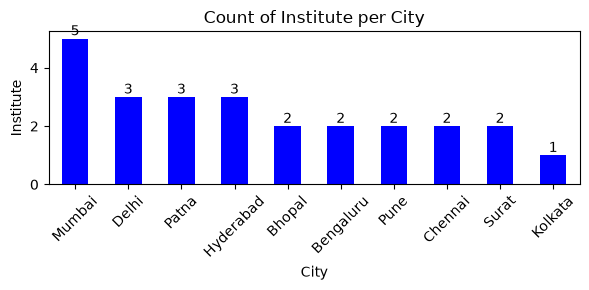

In [102]:
"City with most institutes:",counts.idxmax()


ax=counts.plot(kind='bar',color='Blue',figsize=(6,3))
ax.bar_label(ax.containers[0])
plt.title('Count of Institute per City')
plt.xlabel('City')
plt.ylabel('Institute')
plt.xticks(rotation=45)
plt.tight_layout()

# Done by self

<Axes: xlabel='City'>

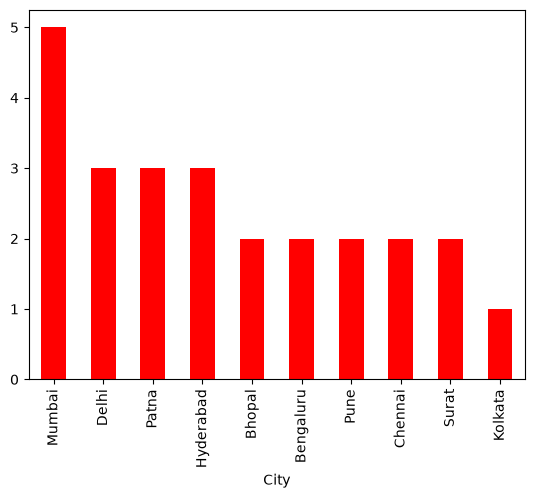

In [103]:
df.groupby('City')['Institute'].nunique().sort_values(ascending=False).plot(kind='bar',color='red')

8. Which course is offered most often, and which least? Show the distribution of the Course column.

In [107]:
cc=df.Course.value_counts()
cc

Course
Data Science    4
AI              3
ML              3
DL              3
Cloud           3
Web Serv        3
AWS             3
BI              2
Networking      1
Name: count, dtype: int64

In [111]:
cc.idxmax()

'Data Science'

* most often offered course.

In [114]:
cc.idxmin()

'Networking'

* least often offered course.

<Axes: title={'center': 'Distribution of Courses'}, xlabel='Courses', ylabel='Count'>

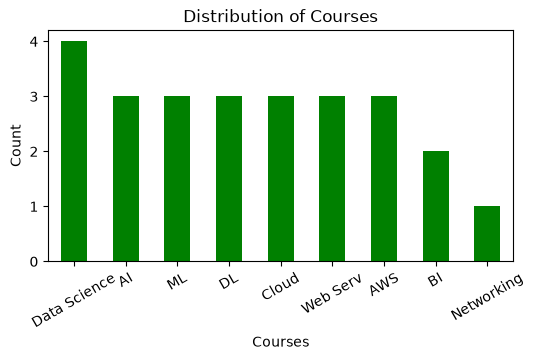

In [167]:
df.Course.value_counts().plot(kind='bar',color='green',figsize=(6,3),title='Distribution of Courses',xlabel='Courses',ylabel='Count',rot=30)

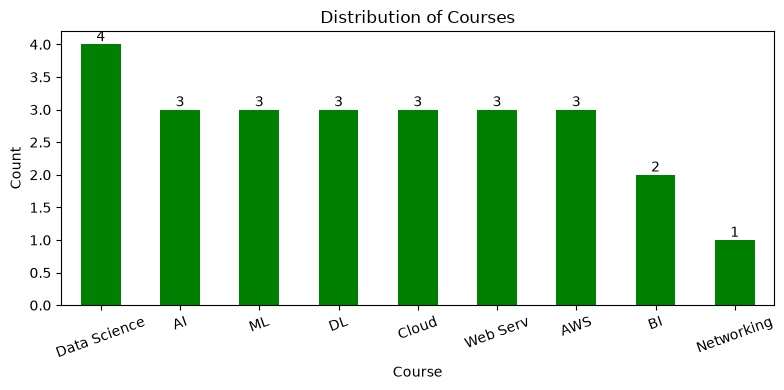

In [122]:
ax = cc.plot(kind='bar',color='green',figsize=(8,4))
ax.bar_label(ax.containers[0])
plt.title('Distribution of Courses')
plt.xlabel('Course')
plt.ylabel('Count')
plt.xticks(rotation=20)
plt.tight_layout()

9. What is the distribution of Duration_Months (mean, median, mode, min, max)? Show it in a histogram or count plot.

In [127]:
ax=df['Duration_Months'].describe()
ax

count    25.000000
mean      6.640000
std       5.203204
min       3.000000
25%       3.000000
50%       4.000000
75%      11.000000
max      18.000000
Name: Duration_Months, dtype: float64

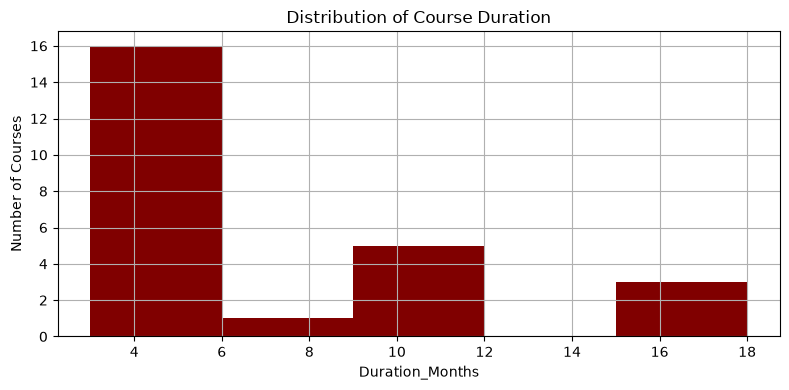

In [143]:
plt.figure(figsize=(8,4))
plt.hist(df['Duration_Months'],bins=5,color='maroon')
plt.title('Distribution of Course Duration')
plt.xlabel('Duration_Months')
plt.ylabel('Number of Courses')
plt.grid()
plt.tight_layout()

* 16 courses lies between 2 to 6 duration months
* 1 course lies between 6 to 9 duration months
* 5 courses lies between 9 to 12 duration months
* no course lies in 12 to 15
* 3 courses lies between 15 to 18 duration months

10. Which state has the most records? Do Maharashtra (MH) and Uttar Pradesh (UP) dominate?

In [144]:
df.State.value_counts() 

State
MH    7
UP    3
AP    3
BR    3
KT    2
MP    2
TN    2
GJ    2
WB    1
Name: count, dtype: int64

- As we can see MH has 7 records which is the highest record compare to other states clearly MH dominates whereas UP has records similar to AP,BR

# Bivariate and Multivariate Analysis

11. What is the average course duration per course? Which courses are the longest and shortest?

In [151]:
avg=df.groupby('Course')['Duration_Months'].mean().sort_values(ascending=False)
avg

Course
AI              18.000000
Data Science    11.000000
BI               7.500000
Web Serv         4.000000
Cloud            3.666667
DL               3.000000
AWS              3.000000
ML               3.000000
Networking       3.000000
Name: Duration_Months, dtype: float64

In [152]:
avg.idxmax()

'AI'

In [153]:
avg.idxmin()

'DL'

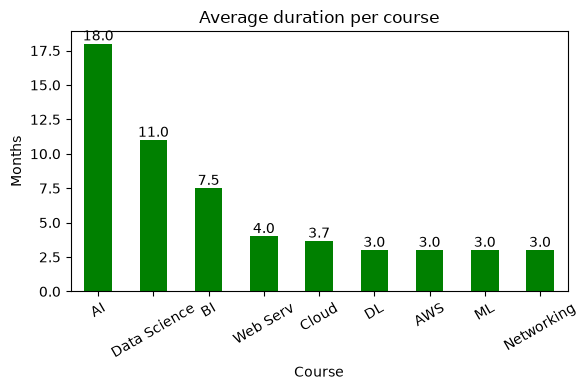

In [155]:
ax = avg.plot(kind="bar", color="green",figsize=(6, 4))
ax.bar_label(ax.containers[0], fmt="%.1f")
plt.title("Average duration per course")
plt.xlabel("Course")
plt.ylabel("Months")
plt.xticks(rotation=30)
plt.tight_layout()

- AI and Data Science courses are longest and AWS,DL,ML,Networking are shortest

12. Is there a relationship between course type and duration? A box plot or groupby would show it. For example, do AI courses always run 18 months and ML always 3?

In [160]:
df.groupby('Course')['Duration_Months'].nunique()

Course
AI              1
AWS             1
BI              2
Cloud           2
DL              1
Data Science    1
ML              1
Networking      1
Web Serv        1
Name: Duration_Months, dtype: int64

In [162]:
pd.crosstab(df.Course,df['Duration_Months']) #builds a table that counts how often each combination of two columns appears.
#The first column becomes the rows (course).
#The second column becomes the columns (duration).
#Each cell is the number of rows with that course and duration.

Duration_Months,3,4,6,9,11,18
Course,,,,,,
AI,0,0,0,0,0,3
AWS,3,0,0,0,0,0
BI,0,0,1,1,0,0
Cloud,1,2,0,0,0,0
DL,3,0,0,0,0,0
Data Science,0,0,0,0,4,0
ML,3,0,0,0,0,0
Networking,1,0,0,0,0,0
Web Serv,0,3,0,0,0,0


# pandas box plot

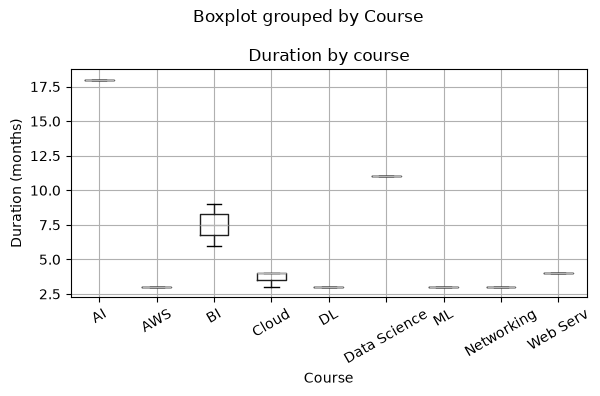

In [165]:
df.boxplot(column="Duration_Months", by="Course", figsize=(6, 4))
plt.title("Duration by course")
plt.xlabel("Course")
plt.ylabel("Duration (months)")
plt.xticks(rotation=30)
plt.tight_layout()

13. Build a crosstab of City vs Course. Which city offers the widest range of courses?

In [168]:
pd.crosstab(df.City,df.Course)

Course,AI,AWS,BI,Cloud,DL,Data Science,ML,Networking,Web Serv
City,,,,,,,,,
Bengaluru,1,0,0,0,0,1,0,0,0
Bhopal,0,0,0,0,1,0,1,0,0
Chennai,0,1,0,1,0,0,0,0,0
Delhi,1,1,1,0,0,0,0,0,0
Hyderabad,1,0,0,1,0,0,1,0,0
Kolkata,0,0,0,0,0,0,0,1,0
Mumbai,0,0,1,1,2,0,0,0,1
Patna,0,1,0,0,0,0,0,0,2
Pune,0,0,0,0,0,2,0,0,0


- Mumbai has widest range of courses

In [170]:
df.groupby('City')['Course'].count()

City
Bengaluru    2
Bhopal       2
Chennai      2
Delhi        3
Hyderabad    3
Kolkata      1
Mumbai       5
Patna        3
Pune         2
Surat        2
Name: Course, dtype: int64

14. Which courses are offered in each state? Show a heatmap of State vs Course.

In [174]:
table=pd.crosstab(df.State,df.Course)
table

Course,AI,AWS,BI,Cloud,DL,Data Science,ML,Networking,Web Serv
State,,,,,,,,,
AP,1,0,0,1,0,0,1,0,0
BR,0,1,0,0,0,0,0,0,2
GJ,0,0,0,0,0,1,1,0,0
KT,1,0,0,0,0,1,0,0,0
MH,0,0,1,1,2,2,0,0,1
MP,0,0,0,0,1,0,1,0,0
TN,0,1,0,1,0,0,0,0,0
UP,1,1,1,0,0,0,0,0,0
WB,0,0,0,0,0,0,0,1,0


- df.groupby(["State", "Course"]).size().unstack(fill_value=0)
- .size() counts the rows in each group, giving a long list like MH, AI -> 3.
- .unstack(fill_value=0) turns the course names into columns, which gives the table shape a heatmap needs.
- fill_value=0 writes 0 where a state doesn’t offer a course. Without it you’d get blank (NaN) cells.

Text(70.83333333333333, 0.5, 'State')

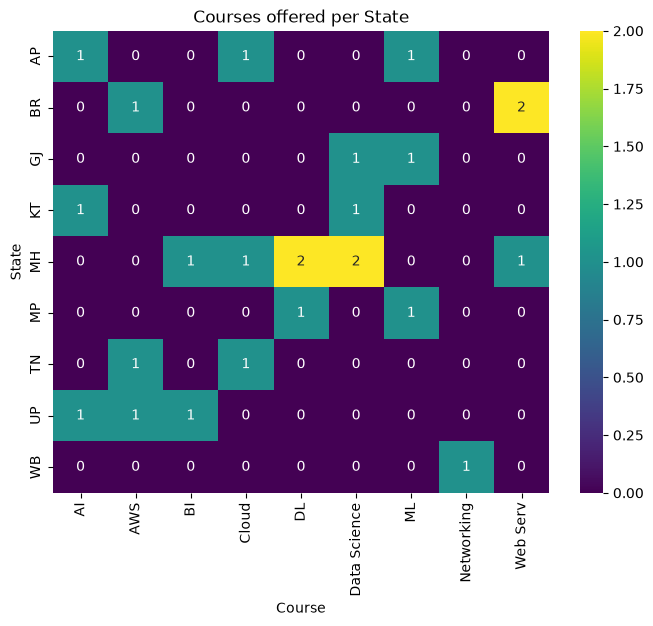

In [186]:
plt.figure(figsize=(8,6))
sns.heatmap(table,annot=True,fmt='d',cmap='viridis')
plt.title("Courses offered per State")
plt.xlabel('Course')
plt.ylabel('State')

15. How does the average duration differ by city or state?

In [191]:
 df.groupby("City")["Duration_Months"].mean().sort_values(ascending=False)

City
Bengaluru    14.500000
Pune         11.000000
Delhi         9.000000
Hyderabad     8.333333
Surat         7.000000
Mumbai        4.400000
Patna         3.666667
Chennai       3.500000
Bhopal        3.000000
Kolkata       3.000000
Name: Duration_Months, dtype: float64

In [192]:
df.groupby("State")["Duration_Months"].mean().sort_values(ascending=False)

State
KT    14.500000
UP     9.000000
AP     8.333333
GJ     7.000000
MH     6.285714
BR     3.666667
TN     3.500000
MP     3.000000
WB     3.000000
Name: Duration_Months, dtype: float64

# For Comparing Charts (From Claude)

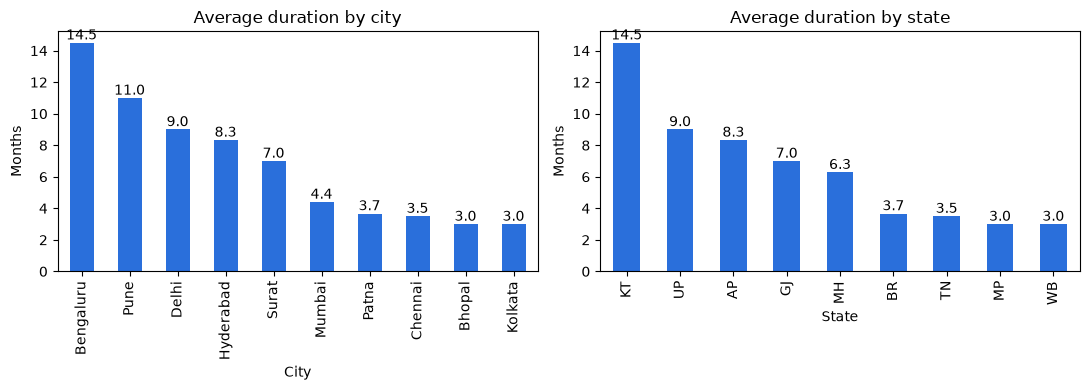

In [190]:
city_avg = df.groupby("City")["Duration_Months"].mean().sort_values(ascending=False)
city_avg
state_avg = df.groupby("State")["Duration_Months"].mean().sort_values(ascending=False)
state_avg
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

city_avg.plot(kind="bar", color="#2a6fdb", ax=axes[0])
axes[0].set_title("Average duration by city")
axes[0].set_ylabel("Months")
axes[0].bar_label(axes[0].containers[0], fmt="%.1f")

state_avg.plot(kind="bar", color="#2a6fdb", ax=axes[1])
axes[1].set_title("Average duration by state")
axes[1].set_ylabel("Months")
axes[1].bar_label(axes[1].containers[0], fmt="%.1f")
plt.tight_layout()


16. Does the institute type (Pvt Ltd vs Ltd vs unspecified) relate to course duration or course category?

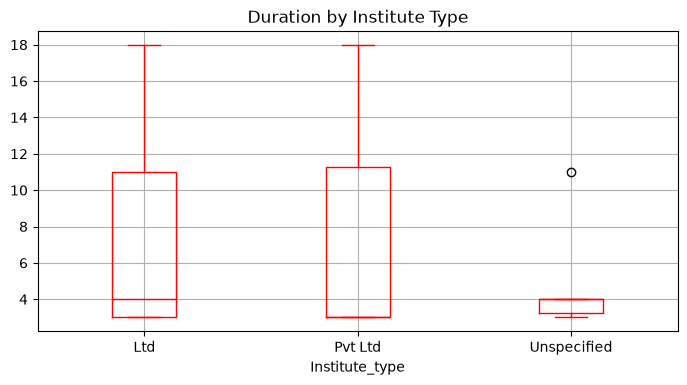

In [196]:
df.boxplot(column='Duration_Months',by='Institute_type',color='red',figsize=(8,4))
plt.suptitle('') # removes the extra automatic title
plt.title('Duration by Institute Type')
plt.ylabel=('Months')

In [200]:
table=pd.crosstab(df['Institute_type'],df.Course)
table

Course,AI,AWS,BI,Cloud,DL,Data Science,ML,Networking,Web Serv
Institute_type,,,,,,,,,
Ltd,1,1,1,0,0,3,2,1,2
Pvt Ltd,2,1,1,1,2,0,1,0,0
Unspecified,0,1,0,2,1,1,0,0,1


Text(0.5, 1.0, 'Institue Type vs Course')

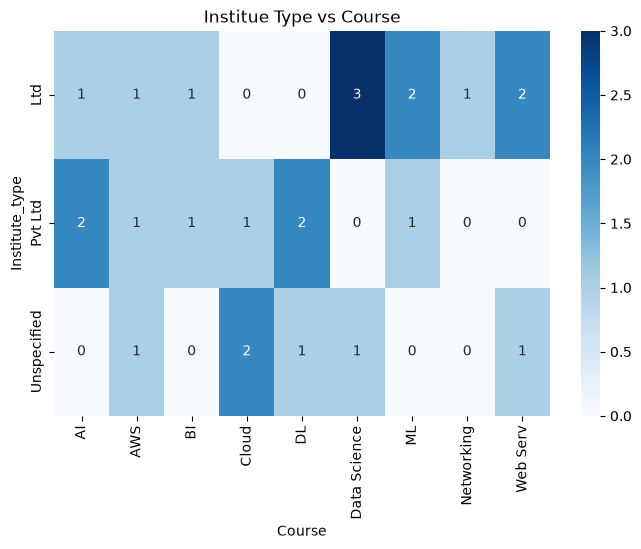

In [206]:
plt.figure(figsize=(8,5))
sns.heatmap(table,annot=True,fmt='d',cmap='Blues')
plt.title('Institue Type vs Course')

# Grouping and Insights

17. Group courses into categories, such as Data/AI (AI, ML, DL, Data Science, BI) and Cloud/Infrastructure (AWS, Cloud, Networking, Web Services). Which category is more common, and how do the categories differ in duration?

In [253]:
category={"AI": "Data/AI", "ML": "Data/AI", "DL": "Data/AI",
    "Data Science": "Data/AI", "BI": "Data/AI",
    "AWS": "Cloud/Infrastructure", "Cloud": "Cloud/Infrastructure",
    "Networking": "Cloud/Infrastructure", "Web Serv": "Cloud/Infrastructure"}
df['Category']=df.Course.str.strip().map(category).fillna('Others')
df

,Sr. No,City,Institute,Course,State,Duration,Institute_type,Duration_Months,Duration_Group,Category
0,1,Mumbai,PQR institute .Pvt,BI,MH,9 Months,Pvt Ltd,9,Long-term,Data/AI
1,2,Delhi,ABC institute .Pvt.LTD,AI,UP,18 Months,Pvt Ltd,18,Long-term,Data/AI
2,3,Bengaluru,MNO institute .Ltd,Data Science,KT,11 Months,Ltd,11,Long-term,Data/AI
3,4,Bhopal,RST institute .Pvt.LTD,ML,MP,3 Months,Pvt Ltd,3,Short-term,Data/AI
4,5,Mumbai,EFG institute .Pvt.LTD,DL,MH,3 Months,Pvt Ltd,3,Short-term,Data/AI
5,6,Hyderabad,LMN institute,Cloud,AP,4 Months,Unspecified,4,Short-term,Cloud/Infrastructure
6,7,Patna,DEF institute .Ltd,Web Serv,BR,4 Months,Ltd,4,Short-term,Cloud/Infrastructure
7,8,Chennai,PQR institute .Pvt.LTD,AWS,TN,3 Months,Pvt Ltd,3,Short-term,Cloud/Infrastructure
8,9,Kolkata,UVW institute .Ltd,Networking,WB,3 Months,Ltd,3,Short-term,Cloud/Infrastructure
9,10,Hyderabad,GHI institute .Ltd,AI,AP,18 Months,Ltd,18,Long-term,Data/AI


In [255]:
# most common category
df.Category.value_counts().idxmax()

'Data/AI'

In [257]:
df.groupby("Category")["Duration_Months"].agg(["mean", "median", "min", "max", "count"])


,mean,median,min,max,count
Category,,,,,
Cloud/Infrastructure,3.500000,3.5,3,4,10
Data/AI,8.733333,9.0,3,18,15


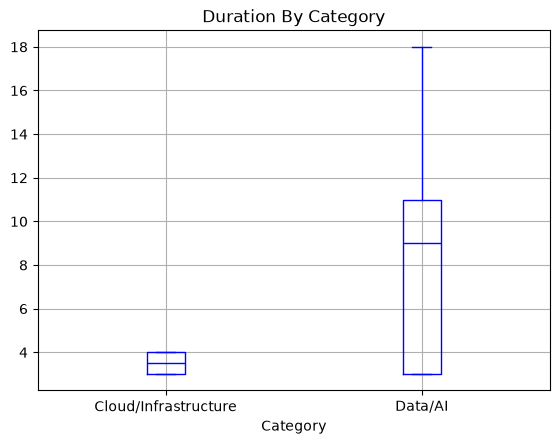

In [258]:
df.boxplot(column='Duration_Months',by='Category',color='blue')
plt.suptitle('')
plt.title('Duration By Category')
plt.ylabel=('Months')

18. Which cities offer both short (3 months or less) and long (11 months or more) courses?

In [213]:
df[df['Duration_Months']<=3].City

3        Bhopal
4        Mumbai
7       Chennai
8       Kolkata
10       Bhopal
13       Mumbai
14        Patna
15        Surat
16        Delhi
21    Hyderabad
22       Mumbai
Name: City, dtype: str

In [214]:
df[df['Duration_Months']>=11].City

1         Delhi
2     Bengaluru
9     Hyderabad
11         Pune
18         Pune
19    Bengaluru
20        Surat
Name: City, dtype: str

19. Which cities or states have only one institute, and which have several? Are institutes concentrated in metros (Mumbai, Delhi, Bengaluru, Hyderabad, Pune)?

In [221]:
city_count=df.groupby('City')["Institute"].nunique().sort_values(ascending=False)
state_count=df.groupby('State')["Institute"].nunique().sort_values(ascending=False)
city_count,state_count

(City
 Mumbai       5
 Delhi        3
 Patna        3
 Hyderabad    3
 Bhopal       2
 Bengaluru    2
 Pune         2
 Chennai      2
 Surat        2
 Kolkata      1
 Name: Institute, dtype: int64,
 State
 MH    7
 AP    3
 BR    3
 UP    3
 GJ    2
 KT    2
 MP    2
 TN    2
 WB    1
 Name: Institute, dtype: int64)

In [227]:
# cities with only one institute
city_count.idxmin()

'Kolkata'

In [228]:
# states with only one institute
state_count.idxmin()

'WB'

In [234]:
metros = ["Mumbai", "Delhi", "Bengaluru", "Hyderabad", "Pune"]
total = df["Institute"].nunique()
df[df["City"].isin(metros)]["Institute"].nunique()

15

In [237]:
df["Institute"].nunique() # total Institutes

25

20. What proportion of courses are short-term (up to 4 months) versus long-term (6 months or more)? Show it in a pie chart.

In [238]:
def duration(months):
    if months<=4:
        return "Short-term"
    elif months>=6:
        return "Long-term"
    else:
        return "In between"

df['Duration_Group']=df['Duration_Months'].apply(duration)

In [239]:
df

,Sr. No,City,Institute,Course,State,Duration,Institute_type,Duration_Months,Duration_Group
0,1,Mumbai,PQR institute .Pvt,BI,MH,9 Months,Pvt Ltd,9,Long-term
1,2,Delhi,ABC institute .Pvt.LTD,AI,UP,18 Months,Pvt Ltd,18,Long-term
2,3,Bengaluru,MNO institute .Ltd,Data Science,KT,11 Months,Ltd,11,Long-term
3,4,Bhopal,RST institute .Pvt.LTD,ML,MP,3 Months,Pvt Ltd,3,Short-term
4,5,Mumbai,EFG institute .Pvt.LTD,DL,MH,3 Months,Pvt Ltd,3,Short-term
5,6,Hyderabad,LMN institute,Cloud,AP,4 Months,Unspecified,4,Short-term
6,7,Patna,DEF institute .Ltd,Web Serv,BR,4 Months,Ltd,4,Short-term
7,8,Chennai,PQR institute .Pvt.LTD,AWS,TN,3 Months,Pvt Ltd,3,Short-term
8,9,Kolkata,UVW institute .Ltd,Networking,WB,3 Months,Ltd,3,Short-term
9,10,Hyderabad,GHI institute .Ltd,AI,AP,18 Months,Ltd,18,Long-term


In [241]:
DG=df['Duration_Group'].value_counts()
DG

Duration_Group
Short-term    16
Long-term      9
Name: count, dtype: int64

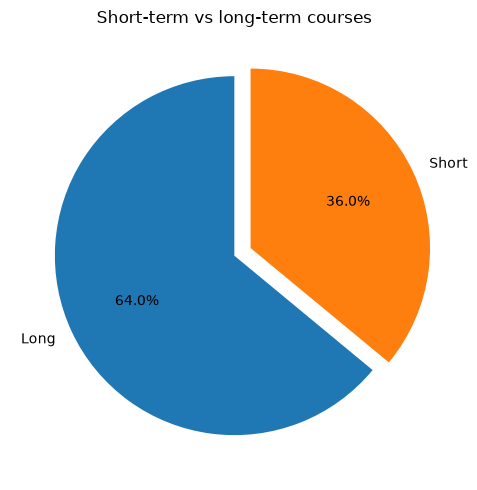

In [247]:
plt.figure(figsize=(5,5))
plt.pie(DG,labels=["Long", "Short"],autopct='%.1f%%',startangle=90,explode=[0,0.1])
plt.title('Short-term vs long-term courses')
plt.tight_layout()